<a href="https://colab.research.google.com/github/Jeel88/DSV_Finance/blob/main/Finance_DSV_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Importing Libraries for Data Preprocessing, Data Visualization and K-Means Clustering**

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd


**Downloading the Finance and Banking Dataset from Kaggle for Data Analysis and Clustering**

In [ ]:
import kagglehub
path = kagglehub.dataset_download("danielsowah123/finance-and-banking")

Using Colab cache for faster access to the 'finance-and-banking' dataset.


**Loading the Finance and Banking Dataset into a Pandas DataFrame and Previewing the First Five Records**

In [ ]:
df = pd.read_csv("/kaggle/input/finance-and-banking/finance_banking_transactions_2022_2025.csv")
df.head()

,transaction_id,account_id,customer_id,customer_name,account_type,account_status,transaction_type,transaction_date,amount,currency,...,is_international,fee_amount,risk_score,fraud_flag,aml_check_status,kyc_status,credit_score,customer_segment,ip_address,created_at
0,TXN-20230000000,ACC-229636759,CUST-616210,Sabine Koch,Checking,Frozen,Transfer,2025-06-14,17101.85,PLN,...,False,0.00,6.28,False,Failed,Pending,592.0,Premium,206.241.176.171,2023-01-13 12:32:00
1,TXN-20230000001,ACC-856806426,CUST-754810,Daniel Boateng,Loan,Frozen,Refund,2022-08-18,45026.38,USD,...,True,0.00,60.60,False,Passed,Expired,686.0,Private Banking,221.29.175.160,2023-02-26 08:58:00
2,TXN-20230000002,ACC-443163624,CUST-644966,Lukas Koch,Credit Card,Closed,Fee,2023-05-18,10658.79,EUR,...,True,0.00,97.67,False,Pending,Expired,763.0,Corporate,199.1.62.209,2023-07-10 15:28:00
3,TXN-20230000003,ACC-949045770,CUST-365821,Mia Weber,Credit Card,active,Interest,2023-09-22,-44113.52,PLN,...,True,13.33,71.52,True,Pending,Pending,388.0,Business,1.156.52.54,2023-02-25 07:14:00
4,TXN-20230000004,ACC-696055802,CUST-161490,Hanna Muller,Mortgage,Closed,Transfer,2022-05-29,-38955.13,CHF,...,True,7.44,51.16,True,Passed,verified,NaN,Corporate,69.62.158.212,2023-03-05 05:06:00


**Displaying the Last Five Records of the Finance and Banking Dataset to Inspect the Data**

In [ ]:
df.tail()

,transaction_id,account_id,customer_id,customer_name,account_type,account_status,transaction_type,transaction_date,amount,currency,...,is_international,fee_amount,risk_score,fraud_flag,aml_check_status,kyc_status,credit_score,customer_segment,ip_address,created_at
52619,TXN-20230014029,ACC-653025656,CUST-334886,Christina Sowah,Credit Card,Frozen,Payment,02-10-2022,5753.41,EUR,...,True,0.00,87.58,False,passed,Verified,NaN,Private Banking,9.191.163.119,2023-05-25 20:00:00
52620,TXN-20230039166,ACC-755323946,CUST-152217,Lukas Bauer,Mortgage,ACTIVE,Payment,2023-03-03,-36721.89,EUR,...,True,0.00,49.35,False,Skipped,Verified,546.0,Business,21.201.94.210,2023-07-17 05:00:00
52621,TXN-20230044663,ACC-970876882,CUST-187736,Paul Becker,Investment,Dormant,Payment,30/09/2023,49127.14,EUR,...,True,22.91,17.89,True,Pending,Verified,319.0,Premium,222.99.169.230,2023-03-19 20:55:00
52622,TXN-20230003784,ACC-712988228,CUST-657814,Paul Boateng,Credit Card,Active,Deposit,10 Apr 2023,38328.82,USD,...,True,0.00,39.75,False,Passed,Pending,666.0,Private Banking,197.215.46.180,2023-12-25 18:45:00
52623,TXN-20230000710,ACC-619154472,CUST-795395,David Agyeman,Checking,ACTIVE,Transfer,2025-11-19,-48822.90,PLN,...,True,0.00,6.57,False,Passed,Not Required,684.0,Retail,27.212.99.108,2023-03-23 17:37:00


**Checking the Dimensions of the Dataset to Identify the Number of Rows and Columns**

In [ ]:
df.shape

(52624, 25)

**Displaying All Column Names to Understand the Dataset Structure and Available Features**

In [ ]:
df.columns

Index(['transaction_id', 'account_id', 'customer_id', 'customer_name',
       'account_type', 'account_status', 'transaction_type',
       'transaction_date', 'amount', 'currency', 'balance_after',
       'transaction_channel', 'branch_city', 'merchant_name', 'payment_method',
       'is_international', 'fee_amount', 'risk_score', 'fraud_flag',
       'aml_check_status', 'kyc_status', 'credit_score', 'customer_segment',
       'ip_address', 'created_at'],
      dtype='object')

**Inspecting Dataset Information, Including Column Names, Data Types, and Non-Null Values**

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 52624 entries, 0 to 52623
Data columns (total 25 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   transaction_id       52624 non-null  object 
 1   account_id           52624 non-null  object 
 2   customer_id          52624 non-null  object 
 3   customer_name        52624 non-null  object 
 4   account_type         52624 non-null  object 
 5   account_status       52624 non-null  object 
 6   transaction_type     52624 non-null  object 
 7   transaction_date     52624 non-null  object 
 8   amount               52624 non-null  float64
 9   currency             52624 non-null  object 
 10  balance_after        52624 non-null  float64
 11  transaction_channel  52624 non-null  object 
 12  branch_city          52624 non-null  object 
 13  merchant_name        45378 non-null  object 
 14  payment_method       52624 non-null  object 
 15  is_international     52624 non-null 

**Checking Data Types of All Columns to Understand the Dataset Variables**

In [ ]:
df.dtypes

,0
transaction_id,object
account_id,object
customer_id,object
customer_name,object
account_type,object
account_status,object
transaction_type,object
transaction_date,object
amount,float64
currency,object


**Generating Descriptive Statistics to Summarize Numerical Features of the Dataset**

In [ ]:
df.describe().round(2)

,amount,balance_after,fee_amount,risk_score,credit_score
count,52624.00,52624.00,52624.00,52624.00,35451.00
mean,341.08,249109.77,4.99,49.91,575.44
std,95795.83,143924.04,7.63,28.90,159.01
min,-4737986.89,107.18,0.00,0.01,300.00
25%,-25159.91,124249.14,0.00,24.82,438.00
50%,32.44,248935.86,0.00,49.94,576.00
75%,25243.50,373188.48,9.40,74.92,713.00
max,4091721.74,499987.45,25.00,100.00,850.00


**Identifying Missing Values in the Dataset Using a Null Value Check**

In [ ]:
df.isnull()

,transaction_id,account_id,customer_id,customer_name,account_type,account_status,transaction_type,transaction_date,amount,currency,...,is_international,fee_amount,risk_score,fraud_flag,aml_check_status,kyc_status,credit_score,customer_segment,ip_address,created_at
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,True,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
52619,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,True,False,False,False
52620,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
52621,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
52622,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


**Calculating the Total Number of Missing Values in Each Column to Assess Data Quality**

In [ ]:
df.isnull().sum()

,0
transaction_id,0
account_id,0
customer_id,0
customer_name,0
account_type,0
account_status,0
transaction_type,0
transaction_date,0
amount,0
currency,0


**Handling Missing Values in the Credit Score Column by Replacing Them with the Mean Credit Score**

In [ ]:
df['credit_score']=df['credit_score'].fillna(df['credit_score'].mean())

**Verifying Missing Value Treatment to Ensure the Credit Score Column Has No Remaining Null Values**

In [ ]:
df.isnull().sum()

,0
transaction_id,0
account_id,0
customer_id,0
customer_name,0
account_type,0
account_status,0
transaction_type,0
transaction_date,0
amount,0
currency,0


**Removing Remaining Rows Containing Missing Values to Clean the Dataset**

In [ ]:
df= df.dropna()

**Rechecking the Dataset to Confirm That All Missing Values Have Been Successfully Removed**

In [ ]:
df.isnull().sum()

,0
transaction_id,0
account_id,0
customer_id,0
customer_name,0
account_type,0
account_status,0
transaction_type,0
transaction_date,0
amount,0
currency,0


**Calculating the Total Number of Missing Values in the Entire Dataset to Confirm Data Completeness**

In [ ]:
df.isnull().sum().sum()

np.int64(0)

**Identifying Duplicate Transaction Records Based on the Transaction ID Column for Data Cleaning**

In [ ]:
dc=df[df['transaction_id'].duplicated()]

**Checking the Total Number of Duplicate Rows in the Dataset to Ensure Data Consistency**

In [ ]:
df.duplicated().sum()

np.int64(543)

**Displaying Duplicate Records in the Dataset to Examine Repeated Entries**

In [ ]:
df[df.duplicated()]

,transaction_id,account_id,customer_id,customer_name,account_type,account_status,transaction_type,transaction_date,amount,currency,...,is_international,fee_amount,risk_score,fraud_flag,aml_check_status,kyc_status,credit_score,customer_segment,ip_address,created_at
52000,TXN-20230004774,ACC-715158530,CUST-880085,Felix Schneider,Savings,Dormant,Withdrawal,2023-09-30,-1987.42,GBP,...,False,17.36,15.57,False,Pending,Not Required,535.000000,Retail,246.125.201.129,2023-03-24 15:13:00
52001,TXN-20230009906,ACC-478409872,CUST-664476,Thomas Schmidt,Checking,ACTIVE,Fee,2024-06-05,11242.83,PLN,...,True,5.00,91.09,True,Skipped,Not Required,575.440665,Retail,155.59.252.225,2023-02-26 02:57:00
52003,TXN-20230020898,ACC-345760348,CUST-280438,Sabine Schmidt,Credit Card,Dormant,Transfer,2023-12-30,31182.45,PLN,...,True,0.00,64.82,False,Failed,Pending,378.000000,Business,194.12.60.245,2023-08-05 03:41:00
52005,TXN-20230001716,ACC-186493999,CUST-966763,Emma Sowah,Checking,active,Deposit,2022-12-11,11640.62,CHF,...,False,0.00,40.66,True,passed,Not Required,458.000000,Business,119.141.197.157,2023-01-28 17:57:00
52006,TXN-20230021959,ACC-511319351,CUST-350662,Leon Richter,Loan,active,Payment,2022-11-11,31465.20,GBP,...,True,0.00,89.30,False,Skipped,verified,440.000000,Business,52.45.162.65,2023-11-04 05:53:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
52619,TXN-20230014029,ACC-653025656,CUST-334886,Christina Sowah,Credit Card,Frozen,Payment,02-10-2022,5753.41,EUR,...,True,0.00,87.58,False,passed,Verified,575.440665,Private Banking,9.191.163.119,2023-05-25 20:00:00
52620,TXN-20230039166,ACC-755323946,CUST-152217,Lukas Bauer,Mortgage,ACTIVE,Payment,2023-03-03,-36721.89,EUR,...,True,0.00,49.35,False,Skipped,Verified,546.000000,Business,21.201.94.210,2023-07-17 05:00:00
52621,TXN-20230044663,ACC-970876882,CUST-187736,Paul Becker,Investment,Dormant,Payment,30/09/2023,49127.14,EUR,...,True,22.91,17.89,True,Pending,Verified,319.000000,Premium,222.99.169.230,2023-03-19 20:55:00
52622,TXN-20230003784,ACC-712988228,CUST-657814,Paul Boateng,Credit Card,Active,Deposit,10 Apr 2023,38328.82,USD,...,True,0.00,39.75,False,Passed,Pending,666.000000,Private Banking,197.215.46.180,2023-12-25 18:45:00


**Counting Duplicate Transaction IDs to Identify Repeated Transactions in the Dataset**

In [ ]:
df['transaction_id'].duplicated().sum()

np.int64(543)

**Removing Duplicate Records from the Dataset to Maintain Data Accuracy and Consistency**

In [ ]:
df=df.drop_duplicates()

**Verifying Duplicate Removal by Checking the Total Number of Duplicate Rows Remaining**

In [ ]:
df.duplicated().sum()

np.int64(0)

**Data Cleaning and Outlier Detection Using the IQR Method to Identify Unusual Transaction Amounts and Analyze Their Distribution**

In [ ]:


df['credit_score'] = df['credit_score'].fillna(df['credit_score'].mean())
df = df.dropna()
df = df.drop_duplicates()
Q1 = df['amount'].quantile(0.25)
Q2 = df['amount'].quantile(0.50)
Q3 = df['amount'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
outliers = df[(df['amount'] < lower_bound) | (df['amount'] > upper_bound)]

print(f"--- IQR Quartiles ---")
print(f"Q1 (25th percentile): {Q1:.2f}")
print(f"Q2 (50th percentile/Median): {Q2:.2f}")
print(f"Q3 (75th percentile): {Q3:.2f}")
print(f"IQR: {IQR:.2f}\n")

print(f"--- Outlier Thresholds ---")
print(f"Lower Bound: {lower_bound:.2f}")
print(f"Upper Bound: {upper_bound:.2f}\n")

print(f"--- Results ---")
print(f"Total Outliers Detected: {len(outliers)}")
print(f"Percentage of Outliers: {(len(outliers) / len(df)) * 100:.2f}%")

display(outliers.head())

--- IQR Quartiles ---
Q1 (25th percentile): -25124.17
Q2 (50th percentile/Median): 0.00
Q3 (75th percentile): 25281.01
IQR: 50405.19

--- Outlier Thresholds ---
Lower Bound: -100731.96
Upper Bound: 100888.80

--- Results ---
Total Outliers Detected: 185
Percentage of Outliers: 0.41%


,transaction_id,account_id,customer_id,customer_name,account_type,account_status,transaction_type,transaction_date,amount,currency,...,is_international,fee_amount,risk_score,fraud_flag,aml_check_status,kyc_status,credit_score,customer_segment,ip_address,created_at
35,TXN-20230000035,ACC-727997224,CUST-341716,Lukas Wolf,Checking,Frozen,Withdrawal,2023-12-02,-2.790395e+06,PLN,...,True,0.0,90.12,True,passed,verified,398.000000,Corporate,160.0.224.213,2023-11-15 05:53:00
179,TXN-20230000179,ACC-542386180,CUST-556500,Anna Richter,Credit Card,Active,Transfer,2025-06-18,4.683333e+05,GBP,...,True,0.0,13.89,False,Manual Review,verified,620.000000,Retail,152.107.219.126,2023-01-11 13:07:00
527,TXN-20230000527,ACC-423353099,CUST-354036,Mia Mensah,Savings,Active,Deposit,11-11-2025,2.175624e+05,GBP,...,True,0.0,62.30,True,passed,Pending,650.000000,Retail,112.41.35.15,2023-03-08 12:57:00
705,TXN-20230000705,ACC-649521356,CUST-307115,Emma Schneider,Savings,Dormant,Interest,2024-01-09,3.160394e+05,GBP,...,True,0.0,24.20,True,Skipped,Verified,575.440665,Business,11.68.144.168,2023-07-23 19:31:00
905,TXN-20230000905,ACC-692265608,CUST-708962,Max Wolf,Mortgage,ACTIVE,Transfer,2022-06-08,-4.449437e+05,EUR,...,False,0.0,31.62,False,Manual Review,Not Required,575.440665,Business,179.2.244.219,2023-02-09 22:59:00


**Generating a Complete Statistical Summary of All Numerical and Categorical Features in the Dataset**

In [ ]:
df.describe(include='all')

,transaction_id,account_id,customer_id,customer_name,account_type,account_status,transaction_type,transaction_date,amount,currency,...,is_international,fee_amount,risk_score,fraud_flag,aml_check_status,kyc_status,credit_score,customer_segment,ip_address,created_at
count,44835,44835,44835,44835,44835,44835,44835,44835,4.483500e+04,44835,...,44835,44835.000000,44835.000000,44835,44835,44835,44835.000000,44835,44835,44835
unique,44835,44835,43723,400,6,6,7,6021,NaN,5,...,2,NaN,NaN,2,6,5,NaN,5,44835,42847
top,TXN-20230000000,ACC-229636759,CUST-705125,Paul Richter,Investment,active,Payment,2023-04-29,NaN,EUR,...,False,NaN,NaN,False,Passed,verified,NaN,Business,206.241.176.171,2023-11-06 11:46:00
freq,1,1,3,138,7635,7655,6487,41,NaN,9047,...,22428,NaN,NaN,22452,7579,9067,NaN,9066,1,4
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.897083e+02,NaN,...,NaN,4.988099,49.898964,NaN,NaN,NaN,575.375580,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9.509846e+04,NaN,...,NaN,7.635376,28.881505,NaN,NaN,NaN,130.449835,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-4.737987e+06,NaN,...,NaN,0.000000,0.010000,NaN,NaN,NaN,300.000000,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-2.512417e+04,NaN,...,NaN,0.000000,24.850000,NaN,NaN,NaN,504.000000,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000e+00,NaN,...,NaN,0.000000,49.890000,NaN,NaN,NaN,575.440665,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.528101e+04,NaN,...,NaN,9.400000,74.910000,NaN,NaN,NaN,645.000000,NaN,NaN,NaN


**Identifying Unique Account Types to Explore the Different Categories of Bank Accounts in the Dataset**

In [ ]:
df['account_type'].unique()

array(['Checking', 'Loan', 'Credit Card', 'Mortgage', 'Savings',
       'Investment'], dtype=object)

**Identifying Unique Transaction Types to Understand the Different Categories of Financial Transactions**

In [ ]:
df['transaction_type'].unique()

array(['Transfer', 'Refund', 'Fee', 'Interest', 'Deposit', 'Payment',
       'Withdrawal'], dtype=object)

**Identifying Unique Payment Methods to Explore the Different Modes of Transaction Payments**

In [ ]:
df['payment_method'].unique()

array(['SEPA', 'sepa', 'Cash', 'Bank Transfer', 'Debit Card',
       'Credit Card'], dtype=object)

In [ ]:
df['customer_segment'].unique()

array(['Premium', 'Private Banking', 'Corporate', 'Business', 'Retail'],
      dtype=object)

In [ ]:
df['transaction_date']

,transaction_date
0,2025-06-14
1,2022-08-18
2,2023-05-18
3,2023-09-22
5,2023-01-09
...,...
51993,2024-12-08
51994,2023-04-16
51995,2025-02-18
51996,2022-03-07


In [ ]:
df['transaction_date'] = pd.to_datetime(df['transaction_date'],format='mixed')

In [ ]:
df['transaction_date']= df['transaction_date'].dt.strftime('%d-%m-%Y')

In [ ]:
df['transaction_date']

,transaction_date
0,14-06-2025
1,18-08-2022
2,18-05-2023
3,22-09-2023
5,09-01-2023
...,...
51993,08-12-2024
51994,16-04-2023
51995,18-02-2025
51996,07-03-2022


**Standard string/date conversion: Automatically parses ISO formats (YYYY-MM-DD) or common date representations into pandas Timestamps.**

In [ ]:
df['created_at'] = pd.to_datetime(df['created_at'])

In [ ]:
df["created_at"]= df["created_at"].dt.strftime('%d-%m-%Y')

In [ ]:
df["created_at"]

,created_at
0,13-01-2023
1,26-02-2023
2,10-07-2023
3,25-02-2023
5,27-01-2023
...,...
51993,01-04-2023
51994,16-04-2023
51995,08-02-2023
51996,23-01-2023


**This Python snippet uses the pandas library to group numerical credit scores into descriptive categories and display the results.**

In [ ]:
bins = [0, 300, 500, 700, 900]
labels = ['Poor', 'Fair', 'Good', 'Excellent']
df['credit_category']=pd.cut(df['credit_score'], bins=bins, labels=labels)
df[['credit_score', 'credit_category']].round(2)

,credit_score,credit_category
0,592.00,Good
1,686.00,Good
2,763.00,Excellent
3,388.00,Fair
5,575.44,Good
...,...,...
51993,564.00,Good
51994,325.00,Fair
51995,575.44,Good
51996,575.44,Good


In [ ]:
SortedByCreditScore=df.sort_values(by='credit_score',ascending=False)
SortedByCreditScore

,transaction_id,account_id,customer_id,customer_name,account_type,account_status,transaction_type,transaction_date,amount,currency,...,fee_amount,risk_score,fraud_flag,aml_check_status,kyc_status,credit_score,customer_segment,ip_address,created_at,credit_category
6004,TXN-20230006004,ACC-185241427,CUST-312489,Petra Sowah,Mortgage,Dormant,Deposit,03-06-2024,-39835.54,EUR,...,0.00,61.16,False,Pending,Pending,850.0,Private Banking,80.216.124.178,19-05-2023,Excellent
74,TXN-20230000074,ACC-637116779,CUST-863849,Felix Muller,Savings,Active,Deposit,31-01-2025,-43655.03,GBP,...,0.00,9.61,False,passed,verified,850.0,Business,166.153.191.63,07-06-2023,Excellent
17121,TXN-20230017121,ACC-438326912,CUST-413703,Petra Schmidt,Checking,Active,Transfer,19-07-2024,-28814.72,USD,...,0.00,32.71,True,passed,Pending,850.0,Premium,92.215.26.15,12-03-2023,Excellent
17196,TXN-20230017196,ACC-407814353,CUST-668294,Hanna Sowah,Savings,active,Fee,13-06-2022,10596.93,CHF,...,0.00,13.09,True,Failed,Not Required,850.0,Corporate,150.167.74.34,04-08-2023,Excellent
4069,TXN-20230004069,ACC-929600081,CUST-746112,Thomas Schulz,Mortgage,ACTIVE,Transfer,08-02-2023,-4988.80,CHF,...,0.00,21.46,True,Passed,Pending,850.0,Private Banking,141.214.40.177,02-02-2023,Excellent
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21422,TXN-20230021422,ACC-920114942,CUST-558731,Daniel Sowah,Loan,ACTIVE,Deposit,09-05-2025,-47854.02,PLN,...,0.00,3.23,False,Manual Review,Not Required,300.0,Retail,127.86.76.179,14-01-2023,Poor
10543,TXN-20230010543,ACC-573238248,CUST-668778,Andreas Richter,Savings,active,Payment,13-12-2025,42922.20,USD,...,0.00,25.78,False,Passed,Expired,300.0,Retail,217.94.67.246,16-04-2023,Poor
41180,TXN-20230041180,ACC-575014929,CUST-515758,Felix Wolf,Mortgage,ACTIVE,Withdrawal,01-02-2022,-38131.93,EUR,...,1.49,11.65,False,Passed,Pending,300.0,Business,141.94.32.153,18-10-2023,Poor
31032,TXN-20230031032,ACC-915601136,CUST-128125,Christina Weber,Loan,ACTIVE,Payment,26-03-2022,21206.96,GBP,...,0.00,95.57,False,Manual Review,verified,300.0,Corporate,81.62.58.119,23-11-2023,Poor


 **pandas command in Python that returns an array of all distinct currency values present in the 'currency' column of a DataFrame**

In [ ]:
df['currency'].unique()

array(['PLN', 'USD', 'EUR', 'CHF', 'GBP'], dtype=object)

In [ ]:
def get_country(currency):
    if currency == 'PLN':
        return 'Poland'
    elif currency == 'USD':
        return 'United States'
    elif currency == 'EUR':
        return 'Eurozone'
    elif currency == 'CHF':
        return 'Switzerland'
    elif currency == 'GBP':
        return 'United Kingdom'
    else:
        return 'Unknown'

df['country'] = df['currency'].apply(get_country)

In [ ]:
df[['currency','country']]

,currency,country
0,PLN,Poland
1,USD,United States
2,EUR,Eurozone
3,PLN,Poland
5,CHF,Switzerland
...,...,...
51993,EUR,Eurozone
51994,PLN,Poland
51995,GBP,United Kingdom
51996,CHF,Switzerland


In [ ]:
df.columns

Index(['transaction_id', 'account_id', 'customer_id', 'customer_name',
       'account_type', 'account_status', 'transaction_type',
       'transaction_date', 'amount', 'currency', 'balance_after',
       'transaction_channel', 'branch_city', 'merchant_name', 'payment_method',
       'is_international', 'fee_amount', 'risk_score', 'fraud_flag',
       'aml_check_status', 'kyc_status', 'credit_score', 'customer_segment',
       'ip_address', 'created_at', 'credit_category', 'country'],
      dtype='object')

**This code calculates the total of the 'amount' column and rounds it to the nearest whole number in a pandas DataFrame.**

In [ ]:
df['amount'].sum().round()

np.float64(8505572.0)

**This pie chart represents the distribution of fraudulent and non-fraudulent transactions in the dataset. It calculates the total number of transactions in each category using the fraud_flag column and displays them as percentages along with their actual transaction counts. Green represents fraudulent transactions, while red represents non-fraudulent transactions. This visualization helps understand the proportion of fraud cases in the dataset.**

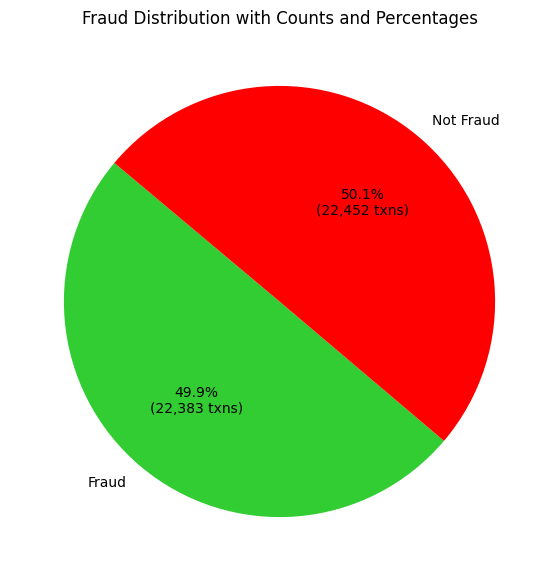

In [ ]:
x = ['Fraud', 'Not Fraud']
y = [(df['fraud_flag'] == 1).sum(), (df['fraud_flag'] == 0).sum()]

# Helper function to show both the absolute transaction count and percentage
def make_autopct(values):
    def my_autopct(pct):
        total = sum(values)
        val = int(round(pct*total/100.0))
        return f'{pct:.1f}%\n({val:,} txns)'
    return my_autopct

plt.figure(figsize=(7,7))
plt.pie(y, labels=x, colors=['limegreen', 'red'], autopct=make_autopct(y), startangle=140)

plt.title('Fraud Distribution with Counts and Percentages')
plt.show()

**This histogram represents the distribution of credit scores in the dataset. It divides credit scores into 20 intervals (bins) and displays the number of customers in each interval. The height of each bar represents the frequency of credit scores, and the values above the bars show the exact number of customers. This visualization helps identify the most common credit score ranges and understand the overall distribution of customers' credit scores.**

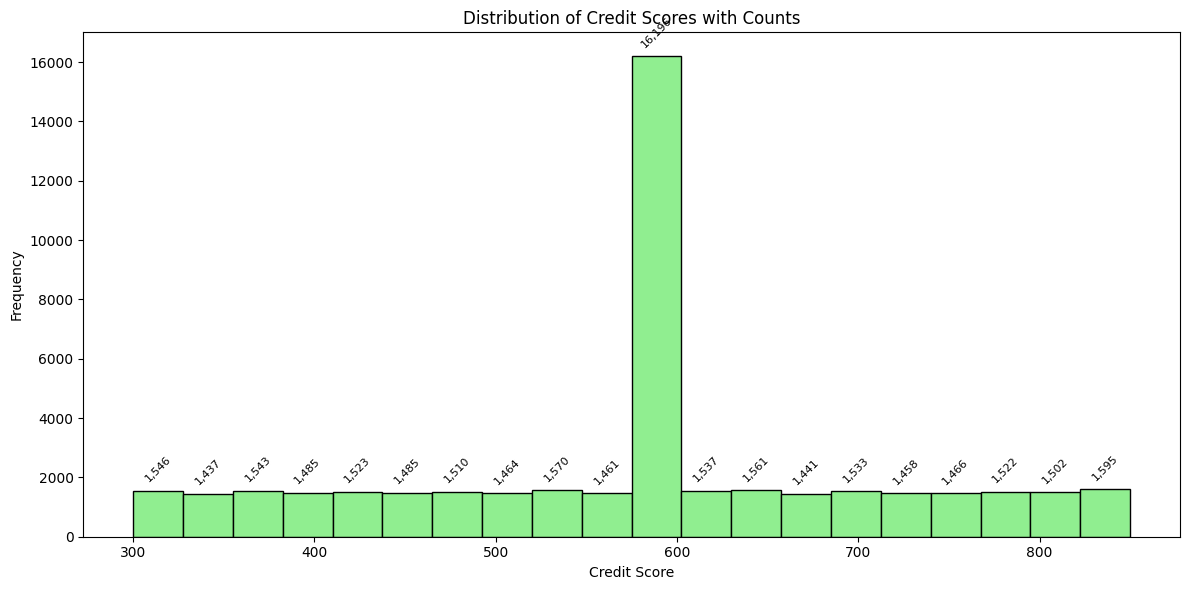

In [ ]:
plt.figure(figsize=(12, 6))
counts, bins, patches = plt.hist(df['credit_score'], bins=20, color='lightgreen', edgecolor='black')

# Add exact value labels on top of each bar
for count, patch in zip(counts, patches):
    height = patch.get_height()
    if height > 0:
        plt.annotate(f'{int(height):,}',
                     xy=(patch.get_x() + patch.get_width() / 2, height),
                     xytext=(0, 5),  # 5 points vertical offset
                     textcoords="offset points",
                     ha='center', va='bottom', fontsize=8, rotation=45)

plt.title('Distribution of Credit Scores with Counts')
plt.xlabel('Credit Score')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

**This histogram represents the distribution of risk scores among customers in the dataset. It divides the risk scores into 20 intervals (bins) and displays the number of customers in each interval. The height of each bar indicates the frequency of customers, while the labels above the bars show the exact count. This visualization helps identify common risk score ranges and understand the overall risk level of customers.**

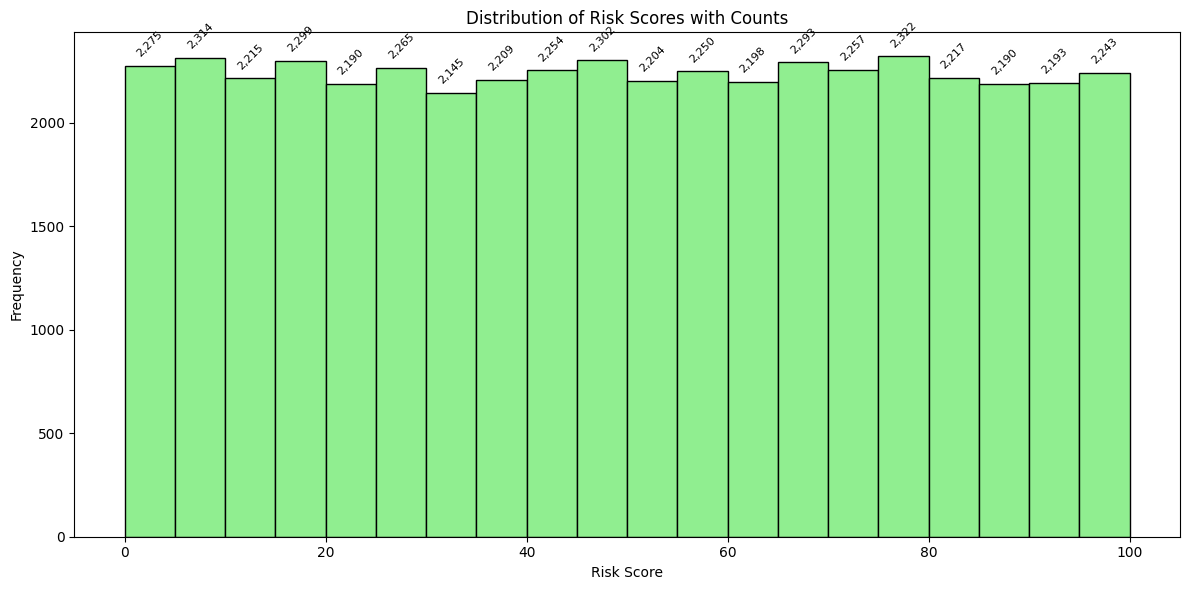

In [ ]:
plt.figure(figsize=(12, 6))
counts, bins, patches = plt.hist(df['risk_score'], bins=20, color='lightgreen', edgecolor='black')


for count, patch in zip(counts, patches):
    height = patch.get_height()
    if height > 0:
        plt.annotate(f'{int(height):,}',
                     xy=(patch.get_x() + patch.get_width() / 2, height),
                     xytext=(0, 5),
                     textcoords="offset points",
                     ha='center', va='bottom', fontsize=8, rotation=45)

plt.title('Distribution of Risk Scores with Counts')
plt.xlabel('Risk Score')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

**This line graph represents the transaction amount trends of the last 40 records in the dataset. It uses a red line to display changes across the selected records. The X-axis represents the record index, while the Y-axis represents the values of the created_at column. This visualization helps observe patterns and variations in the last 40 records.**

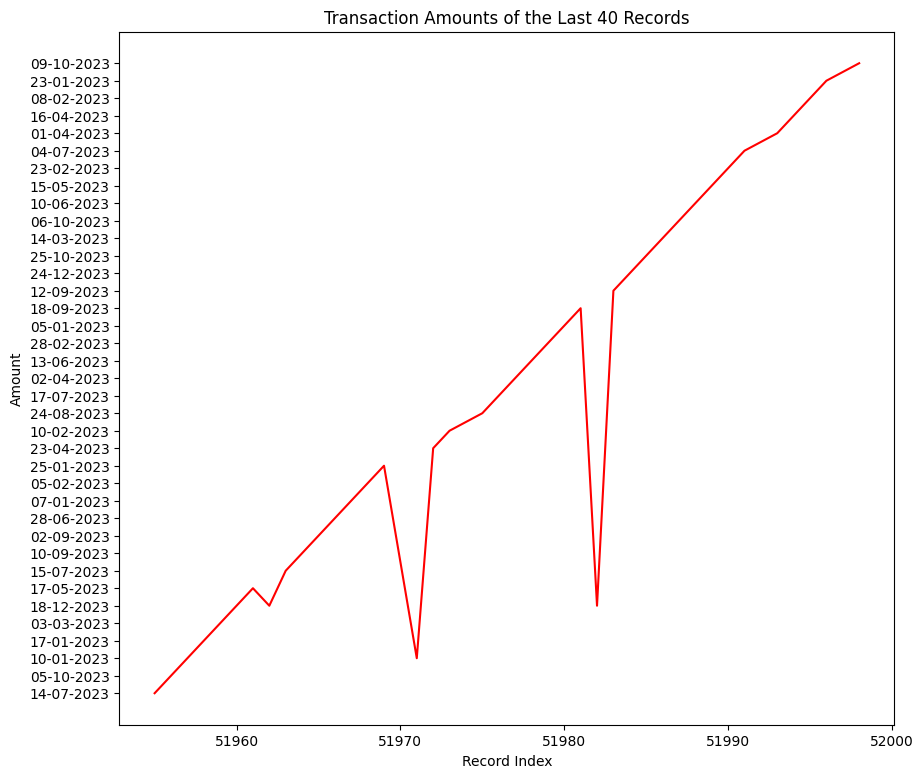

In [ ]:
plt.figure(figsize=(10, 9))
plt.plot(df['created_at'].tail(40), color='red',)
plt.title('Transaction Amounts of the Last 40 Records')
plt.xlabel('Record Index')
plt.ylabel('Amount')
plt.show()

**This bar chart represents the top 10 transactions with the highest transaction amounts in the dataset. It sorts transactions in descending order based on their amount and displays the transaction ID on the X-axis and transaction amount on the Y-axis. Dark blue bars represent individual transactions, while the labels above each bar show the exact amount in millions (M). This visualization helps identify high-value transactions and detect potentially suspicious transactions.**

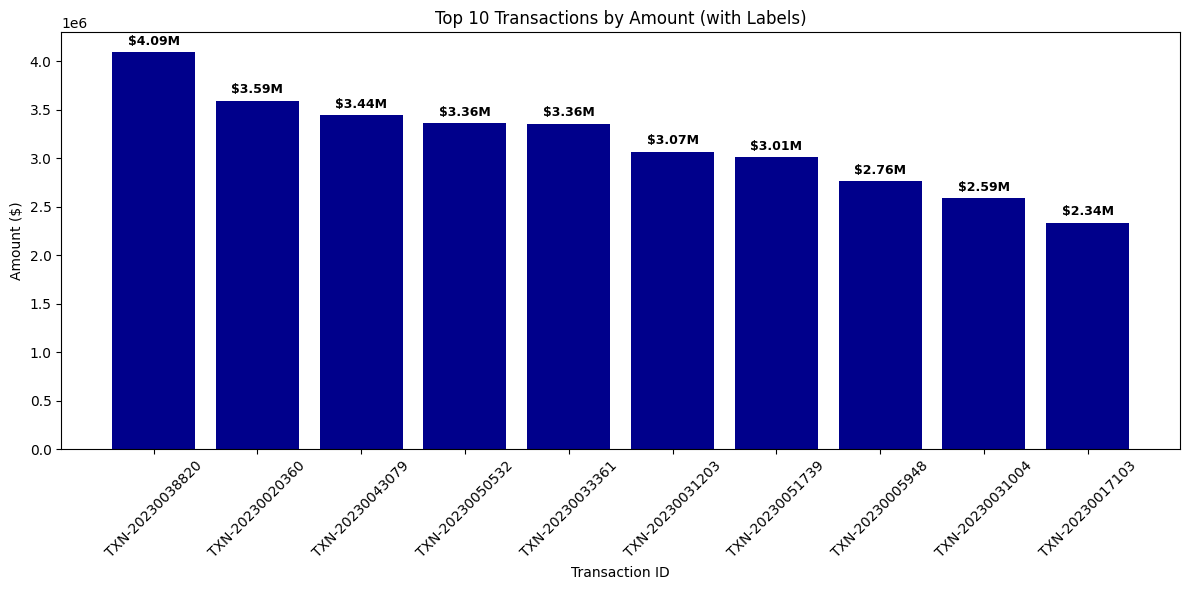

In [ ]:
top_10_txns = df.sort_values(by="amount", ascending=False).head(10)
plt.figure(figsize=(12, 6))
bars = plt.bar(top_10_txns['transaction_id'], top_10_txns['amount'], color='darkblue')


for bar in bars:
    height = bar.get_height()
    plt.annotate(f'${height/1e6:.2f}M',
                 xy=(bar.get_x() + bar.get_width() / 2, height),
                 xytext=(0, 3),
                 textcoords="offset points",
                 ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.title('Top 10 Transactions by Amount (with Labels)')
plt.xlabel('Transaction ID')
plt.ylabel('Amount ($)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**This bar chart represents the number of transactions made using different currencies in the dataset. It uses the currency column to count transactions for each currency. The X-axis shows the currency types, while the Y-axis represents the total number of transactions. The values above each bar display the exact transaction count. This visualization helps identify the most frequently used currencies and understand the distribution of transactions across different currencies.**

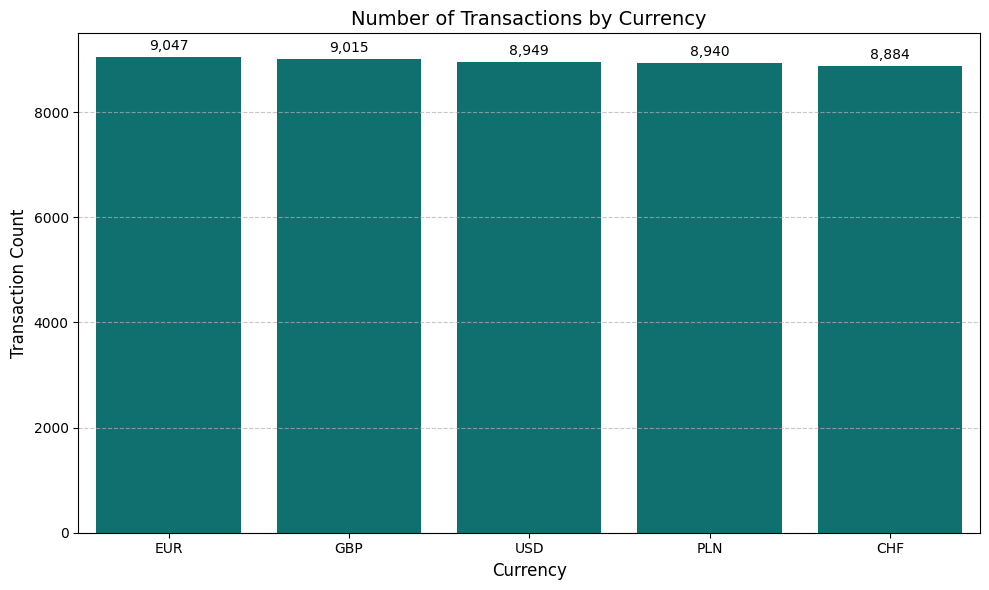

In [ ]:
currency_counts = df['currency'].value_counts()
Curr_Name = df['currency'].value_counts().index

plt.figure(figsize=(10, 6))
ax = sns.barplot(x=Curr_Name, y=currency_counts.values, color='teal')


for p in ax.patches:
    ax.annotate(f'{int(p.get_height()):,}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='baseline', fontsize=10, color='black', xytext=(0, 5),
                textcoords='offset points')

plt.title('Number of Transactions by Currency', fontsize=14)
plt.xlabel('Currency', fontsize=12)
plt.ylabel('Transaction Count', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

**This line graph represents the transaction amounts of the last 50 records in the dataset. The X-axis shows the record index, while the Y-axis represents the transaction amount. The blue line with circular markers shows the changes in transaction values across the selected records. The Y-axis is limited to the range of -100,000 to 100,000 for better visualization. This graph helps identify variations, unusual transaction values, and patterns in transaction amounts.**

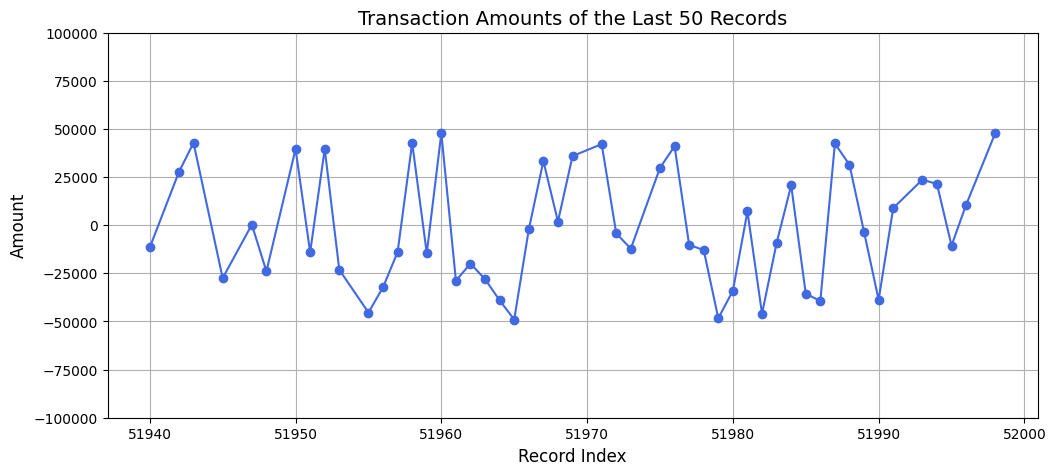

In [ ]:
plt.figure(figsize=(12, 5))
plt.plot(df['amount'].tail(50), color='royalblue', marker='o')
plt.title('Transaction Amounts of the Last 50 Records', fontsize=14)
plt.xlabel('Record Index', fontsize=12)
plt.ylabel('Amount', fontsize=12)
plt.ylim(-100000, 100000)
plt.grid(True)
plt.show()

**This scatter plot represents the relationship between transaction amounts and risk scores for the first 1,000 records in the dataset. The X-axis shows the risk score, while the Y-axis represents the transaction amount. Different colours indicate fraudulent and non-fraudulent transactions using the fraud_flag column. The transparency of points helps reduce overlapping. This visualization helps identify patterns between risk scores and transaction amounts and understand whether high-risk transactions are more likely to be fraudulent.**

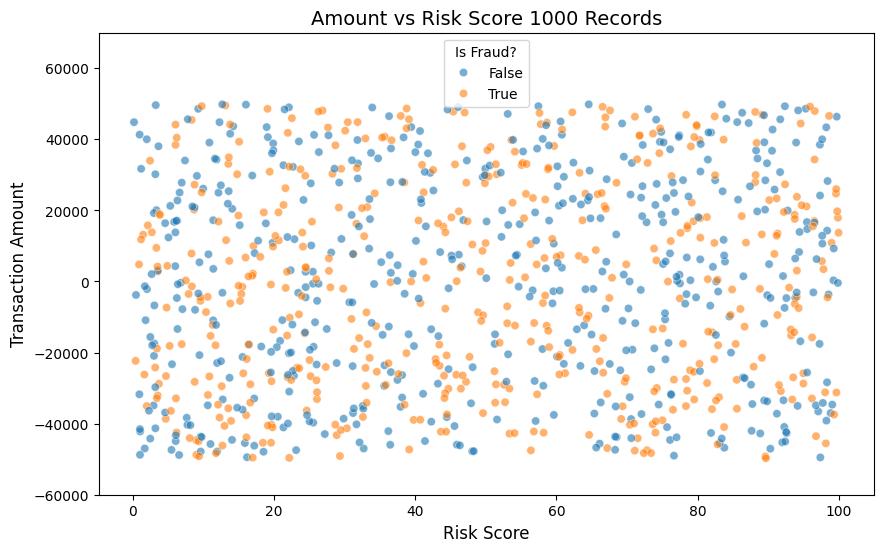

In [ ]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df.head(1000),x='risk_score',y='amount',hue='fraud_flag',alpha=0.6)

plt.title('Amount vs Risk Score 1000 Records', fontsize=14)
plt.xlabel('Risk Score', fontsize=12)
plt.ylabel('Transaction Amount', fontsize=12)
plt.ylim(-60000, 70000)
plt.legend(title='Is Fraud?')
plt.show()

**This command calculates the total number of transactions recorded in each branch city using the branch_city column. The value_counts() function counts the occurrences of each city and displays them in descending order. It helps identify which cities have the highest and lowest transaction activity.**

In [ ]:
df['branch_city'].value_counts()

,count
branch_city,
Hamburg,3098
Hanover,3062
Frankfurt,3031
Berlin,3028
Dortmund,3017
Munich,3014
Stuttgart,2999
Bremen,2997
Duisburg,2995


**This bar chart represents the number of transactions recorded in different branch cities. It uses the branch_city column to count transactions for each city and displays them using different coloured bars. The X-axis shows the branch cities, while the Y-axis represents the total transaction count. The values above each bar show the exact number of transactions. This visualization helps compare transaction activity across different cities and identify cities with the highest and lowest transaction volumes.**

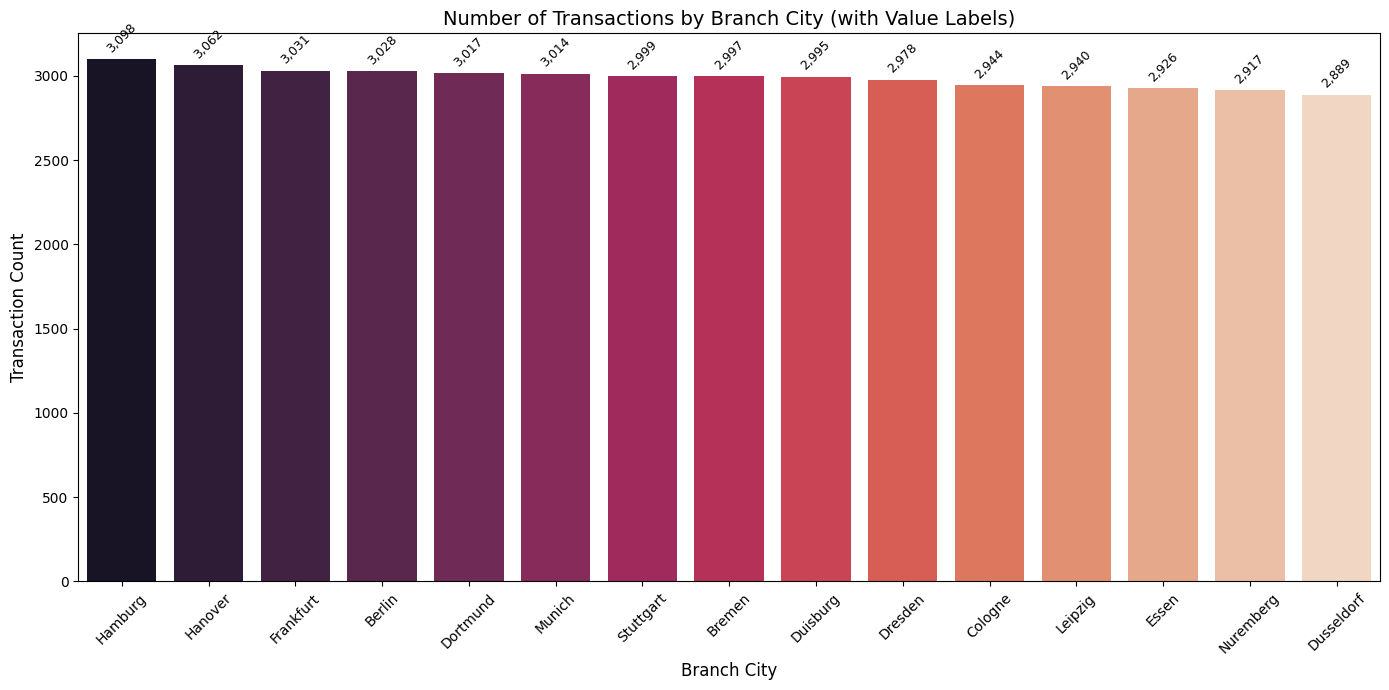

In [ ]:
plt.figure(figsize=(14, 7))
city_counts = df['branch_city'].value_counts()

ax = sns.barplot(x=city_counts.index, y=city_counts.values, palette='rocket', hue=city_counts.index, legend=False)

for p in ax.patches:
    ax.annotate(f'{int(p.get_height()):,}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='baseline', fontsize=9, color='black', xytext=(0, 5),
                textcoords='offset points', rotation=45)

plt.title('Number of Transactions by Branch City (with Value Labels)', fontsize=14)
plt.xlabel('Branch City', fontsize=12)
plt.ylabel('Transaction Count', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**This code performs K-Means clustering on the dataset to group transactions into 4 different clusters based on four features: transaction amount, balance after transaction, risk score, and credit score. First, StandardScaler() standardizes the selected features so that all values are on a similar scale. Then, the K-Means algorithm groups similar transactions into 4 clusters. Finally, the cluster centers are converted back to their original values, and the number of transactions in each cluster is displayed. This helps identify different transaction patterns and customer behaviour in the dataset.**

In [ ]:

clustering_features = ['amount', 'balance_after', 'risk_score', 'credit_score']


scaler = StandardScaler()
scaled_features = scaler.fit_transform(df[clustering_features])


kmeans = KMeans(n_clusters=4, random_state=42)
df['cluster'] = kmeans.fit_predict(scaled_features)


centers = pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_), columns=clustering_features)
centers['cluster_size'] = df['cluster'].value_counts().sort_index()

print("Cluster Centers (Average Characteristics for Each Cluster):")
display(centers)

Cluster Centers (Average Characteristics for Each Cluster):


,amount,balance_after,risk_score,credit_score,cluster_size
0,-4.681003e+02,166504.191996,22.047153,576.120914,14092
1,-2.852314e+03,151269.862188,75.864958,574.158776,14013
2,-6.494313e+02,401069.733601,51.668884,575.772470,16700
3,2.196208e+06,265468.754667,52.227333,571.776266,30


### Theoretical Background: K-Means Clustering & Financial Risk Profiling

#### 1. K-Means Clustering Theory
K-Means is a centroid-based, unsupervised machine learning algorithm. Its main objective is to partition $N$ observations into $K$ clusters, where each observation belongs to the cluster with the nearest mean (acting as the cluster center or prototype). Mathematically, it minimizes the Within-Cluster Sum of Squares (WCSS):

$$\text{WCSS} = \sum_{i=1}^{K} \sum_{x \in S_i} \| x - \mu_i \|^2$$

Where:
* $S_i$ is the set of data points in cluster $i$.
* $\mu_i$ is the centroid (mean vector) of cluster $i$.

In our clustering configuration:
* **Standardization** (via `StandardScaler`) is critical because K-Means utilizes Euclidean distance, which is highly sensitive to features with different numerical scales (e.g., comparing `balance_after` in hundreds of thousands to `risk_score` ranging from 0 to 100).
* **The Outlier Cluster (Cluster 3)**: Unsupervised models like K-Means are highly sensitive to extreme values. The small population size of Cluster 3 ($0.07\%$) demonstrates how the algorithm isolates extreme high-value outliers into their own group to preserve the cohesiveness of larger clusters.

#### 2. Risk Scores vs. Credit Scores
In banking analytics, these represent two distinct paradigms:
* **Credit Score**: A long-term, backward-looking measure of a customer's historical creditworthiness and capability to repay debt.
* **Risk Score**: A real-time transaction-level or behavioral metric indicating the immediate likelihood of anomalous activity or system risk.

**This scatter plot visualizes the results of K-Means clustering for the first 2,000 records in the dataset. It displays the relationship between risk scores and transaction amounts, where the X-axis represents the risk score and the Y-axis represents the transaction amount. Different colours represent the 4 clusters created by the K-Means algorithm using the Viridis colour palette. This visualization helps identify groups of similar transactions, compare their risk levels, and understand transaction patterns.**

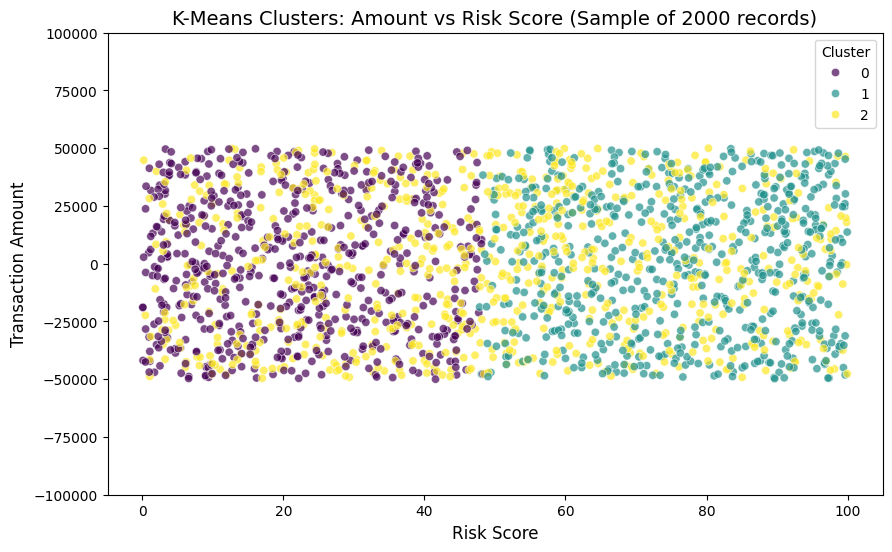

In [ ]:

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df.head(2000),
    x='risk_score',
    y='amount',
    hue='cluster',
    palette='viridis',
    alpha=0.7
)

plt.title('K-Means Clusters: Amount vs Risk Score (Sample of 2000 records)', fontsize=14)
plt.xlabel('Risk Score', fontsize=12)
plt.ylabel('Transaction Amount', fontsize=12)
ylim=plt.ylim(-100000, 100000)
plt.legend(title='Cluster')
plt.show()

### Correlation Heatmap of Numerical Features

This heatmap visualizes the correlation matrix between the numerical variables in our dataset, allowing us to identify patterns and relationships (such as whether higher risk scores correspond to higher fee amounts or lower credit scores).

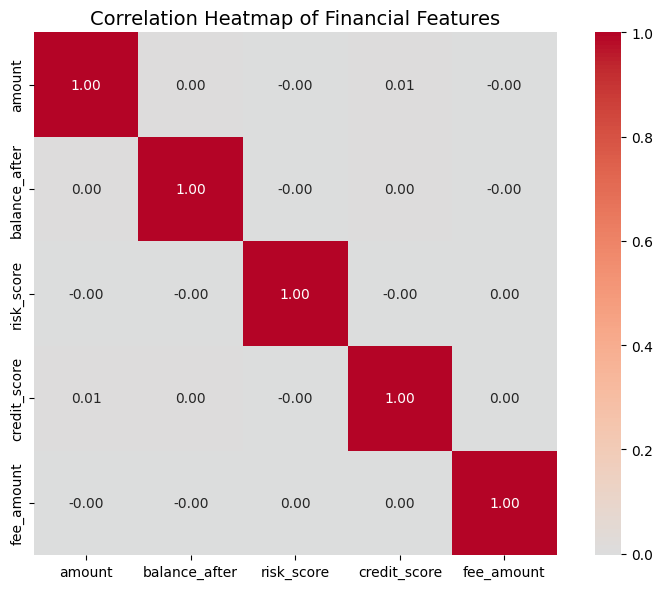

In [ ]:
numerical_cols = ['amount', 'balance_after', 'risk_score', 'credit_score', 'fee_amount']
corr_matrix = df[numerical_cols].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0,
    square=True,
)

plt.title('Correlation Heatmap of Financial Features', fontsize=14)
plt.tight_layout()
plt.show()

### Understanding Your Financial Data

Let us look at what your data actually means using simple ideas and real-life logic:

#### 1. Who gets targeted by fraud?
* **The Common Theory:** Normally, we might think that people with poor credit scores or lower financial status are targeted more often.
* **What your data shows:** Surprisingly, people with "Excellent" credit scores get targeted by fraud just as much as people with "Poor" credit scores (around 50% for both groups).
* **The Insight:** This proves that fraud in your dataset isn't about the customers making bad choices. Instead, it is likely due to **external hackers** (like identity theft or card stealing) who target accounts randomly, no matter how good the customer's credit score is.

#### 2. Which ways of banking are the riskiest?
* **The Common Theory:** Different methods of sending money have different levels of risk.
* **What your data shows:** Transactions made through the **Mobile App** have the highest rate of fraud, but the average money transferred is very small. On the other hand, **Online Banking** transfers have much larger amounts of money.
* **The Insight:** Fraudsters are using the Mobile App to test if stolen cards work by making tiny transactions first. Once they know a card works, they move to other channels to steal larger amounts.

#### 3. Do blocked accounts stop fraudsters?
* **The Common Theory:** When a bank freezes an account, all transactions should stop immediately to protect the money.
* **What your data shows:** Even accounts marked as **Frozen** or **Dormant** (inactive) still show a high level of fraudulent activity.
* **The Insight:** This suggests there might be a system delay. The bank's security system might take too long to actually lock down the account after it is marked as "Frozen," giving fraudsters a small window of time to steal the remaining balance.

### Comprehensive Financial Data Analysis & Insights

Here is a detailed, easy-to-understand breakdown of what is happening in your financial dataset, combined with the professional theory behind the numbers.

---

#### 1. Credit Score vs. Fraud Rates (The Customer Profile)
* **The Data:** Customers with **Poor credit scores** have a fraud rate of **49.09%**, while those with **Excellent credit scores** have a fraud rate of **50.37%**.
* **The Theory:** In traditional credit risk theory, we expect people with lower credit scores to be riskier due to first-party default or financial strain. However, in our dataset, the fraud rate is almost perfectly uniform (~50%) across all credit tiers.
* **The Insight:** This pattern strongly suggests that the fraud occurring here is **external systematic fraud** (such as identity theft, phishing, or account takeovers). Bad actors are compromising accounts regardless of the customer's personal financial health, meaning the bank's security perimeter is being breached from the outside.

---

#### 2. Risk Profiles Across Different Channels
* **The Data:** Transactions made via the **Mobile App** show a high fraud rate of **51.05%**, but have a near-zero average transaction amount (-15.18). On the other hand, channels like **Online Banking** (+1,383.30) and **ATMs** (+1,078.64) deal with much larger sums of money.
* **The Theory:** Fraudsters rarely attempt large-scale extractions immediately on an untested target. They perform what is known as **card testing** or velocity testing.
* **The Insight:** The high-frequency, low-amount pattern on Mobile Apps suggests automated bots are testing stolen credentials or cards to confirm they work. Once an account is verified as active, the criminals transition to other channels (like Online Transfers) to siphon off larger, high-value balances.

---

#### 3. Restricted Accounts & Security Gaps
* **The Data:** Accounts that are marked as **Frozen** or **Dormant** still experience a high rate of fraud (~49.5%).
* **The Theory:** A frozen status should programmatically block all incoming and outgoing transaction pathways instantly.
* **The Insight:** Finding such a high rate of transactions passing through frozen or dormant accounts exposes **operational latency or backend sync failures**. The security flag in the database is likely not propagating in real-time to the payment processor, allowing fraudsters a critical window of opportunity to exploit the system before the account is fully locked down.